# 07 — Evaluation on the untouched test period, explainability and error analysis

**Stage 11.** The tuned models from notebook 06 and the three baselines are scored **once** on the test period (purchases May–Jul 2018, 18,944 orders, 3.81% late). Every decision threshold is chosen on validation (Mar–Apr 2018) and then applied unchanged to test.

| Metric | Why |
|---|---|
| **PR-AUC** (primary) | Focuses on the rare late class; not inflated by the many on-time orders |
| Recall, precision, F1 on late orders | Recall = share of late orders caught; precision = share of alerts that were real |
| Balanced accuracy | Average recall over both classes, fair under imbalance |
| ROC-AUC | For comparison with published work |
| Confusion matrix | Shows exactly what each error type costs |
| Brier score + calibration curve | The probabilities feed the cost decision (notebook 08), so they must be trustworthy |
| PR-AUC per test month | Performance as the late rate drifts |

In [1]:
import sys, time, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, psutil, joblib, shap
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix
from sklearn.tree import plot_tree, export_text
from olist import config as C
from olist.baselines import CORE_FEATURES
from olist.evaluate import scores, best_f1_threshold, per_period, bootstrap_diff, bootstrap_ci
from olist.modeling import load_task_a, task_a_sets

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"07_{name}.png", bbox_inches="tight")
RESULTS = ROOT / "reports" / "results"; MODELS = ROOT / "models"

pop = load_task_a(); S = task_a_sets(pop)
TRAIN, VAL, TEST = S["train"], S["val"], S["test"]
F = json.load(open(MODELS / "task_a_features.json"))
NAMES = {"lgbm": "LightGBM", "forest": "Random forest", "logreg": "Logistic regression", "tree": "Decision tree",
         "core_logreg": "Baseline: core logreg", "business_rule": "Baseline: business rule", "majority": "Baseline: majority"}
models = {k: joblib.load(MODELS / f"task_a_{k}.joblib") for k in NAMES}
feats = {k: (CORE_FEATURES if k == "core_logreg" else F) for k in NAMES}
P = {k: {s: m.predict_proba(d[feats[k]])[:, 1] for s, d in [("train", TRAIN), ("val", VAL), ("test", TEST)]} for k, m in models.items()}
cv = pd.read_csv(RESULTS / "06_model_comparison.csv", index_col=0)["cv_pr_auc"]
print(f"test: {len(TEST):,} orders, {int(TEST.late_day.sum()):,} late ({TEST.late_day.mean():.2%}) | RSS {rss()}")

test: 18,944 orders, 722 late (3.81%) | RSS 601 MB


## 1. The results table (thresholds chosen on validation)

In [2]:
rows, THR = [], {}
for k in NAMES:
    thr = 0.5 if k in ("majority", "business_rule") else best_f1_threshold(VAL.late_day, P[k]["val"])
    THR[k] = thr
    st = scores(TEST.late_day, P[k]["test"], thr)
    lo, hi = bootstrap_ci(TEST.late_day, P[k]["test"], n=500)
    rows.append({"model": NAMES[k], "train_pr_auc": scores(TRAIN.late_day, P[k]["train"])["pr_auc"],
                 "cv_pr_auc": cv.get({"core_logreg": "baseline: core logreg"}.get(k, k), np.nan),
                 "val_pr_auc": scores(VAL.late_day, P[k]["val"])["pr_auc"], "test_pr_auc": st["pr_auc"],
                 "test_pr_auc_95ci": f"[{lo:.3f}, {hi:.3f}]", "test_roc_auc": st["roc_auc"], "test_brier": st["brier"],
                 "threshold (from val)": thr, "test_precision": st["precision"], "test_recall": st["recall"], "test_f1": st["f1"],
                 "test_balanced_acc": st["balanced_acc"], "test_flagged_%": st["flagged_%"]})
res = pd.DataFrame(rows).set_index("model")
res.to_csv(RESULTS / "07_test_results.csv")
res.round(3)

,train_pr_auc,cv_pr_auc,val_pr_auc,test_pr_auc,test_pr_auc_95ci,test_roc_auc,test_brier,threshold (from val),test_precision,test_recall,test_f1,test_balanced_acc,test_flagged_%
model,,,,,,,,,,,,,
LightGBM,0.365,0.157,0.217,0.088,"[0.077, 0.103]",0.700,0.036,0.076,0.086,0.460,0.144,0.633,20.450
Random forest,0.485,0.149,0.201,0.084,"[0.073, 0.097]",0.691,0.037,0.116,0.086,0.382,0.140,0.610,16.987
Logistic regression,0.158,0.182,0.221,0.083,"[0.073, 0.095]",0.690,0.037,0.105,0.082,0.366,0.134,0.602,16.918
Decision tree,0.171,0.138,0.161,0.051,"[0.046, 0.056]",0.613,0.037,0.057,0.055,0.402,0.096,0.564,27.935
Baseline: core logreg,0.124,NaN,0.138,0.110,"[0.094, 0.132]",0.707,0.036,0.053,0.087,0.446,0.146,0.630,19.537
Baseline: business rule,0.065,NaN,0.125,0.042,"[0.038, 0.046]",0.542,0.403,0.500,0.046,0.482,0.084,0.542,40.166
Baseline: majority,0.056,NaN,0.118,0.038,"[0.036, 0.041]",0.500,0.037,0.500,0.000,0.000,0.000,0.500,0.000


**Finding.** Logistic regression was selected on validation (0.221). On the test period it scores **PR-AUC 0.083 (95% CI 0.073–0.095)** and ROC-AUC 0.690: 2.2× the 3.8% base rate. At its validation-chosen threshold it flags 16.9% of test orders and catches 36.6% of the late ones, with 8.2% of alerts correct. LightGBM is the strongest tuned model on test (0.088, recall 46%), followed by the random forest (0.084) and the decision tree (0.051). Every tuned model clearly beats the majority class (0.038) and the business rule. The rule's PR-AUC is barely above the base rate (0.042) and it flags 40% of all orders.

**However, the five-feature core logistic regression beats every tuned model on test: 0.110 (95% CI 0.094–0.132), ROC-AUC 0.707.** It was the weakest of the three on validation (0.138 against 0.221). The disclosure below and the post-hoc diagnosis in section 6 examine why.

### Disclosure: the first look at the test set

The test period was first scored with an earlier pipeline: 47 features, which still included five "clock" features, and a LightGBM whose early stopping watched the scored month and ended up with only 10 trees. Those numbers are kept below. They triggered the label-free stationarity audit in notebook 04 (section 6), which removed the clock features before the models were re-tuned. Because the test set was looked at twice, the final numbers above are somewhat optimistic compared with a single blind evaluation.

In [3]:
first = pd.read_csv(RESULTS / "07_first_pass_test_results.csv", index_col=0)[["val_pr_auc", "test_pr_auc", "test_roc_auc"]]
compare = first.join(res[["val_pr_auc", "test_pr_auc", "test_roc_auc"]], lsuffix=" (first pass, 47 features)", rsuffix=" (final, 42 features)")
compare.round(3)

,"val_pr_auc (first pass, 47 features)","test_pr_auc (first pass, 47 features)","test_roc_auc (first pass, 47 features)","val_pr_auc (final, 42 features)","test_pr_auc (final, 42 features)","test_roc_auc (final, 42 features)"
model,,,,,,
LightGBM,0.181,0.047,0.593,0.217,0.088,0.700
Random forest,0.243,0.057,0.638,0.201,0.084,0.691
Logistic regression,0.230,0.078,0.682,0.221,0.083,0.690
Decision tree,0.236,0.049,0.587,0.161,0.051,0.613
Baseline: core logreg,0.138,0.110,0.707,0.138,0.110,0.707
Baseline: business rule,0.125,0.042,0.542,0.125,0.042,0.542
Baseline: majority,0.118,0.038,0.500,0.118,0.038,0.500


**Finding.** Removing the clock features improved every tuned model on test: logistic regression 0.078 → 0.083, random forest 0.057 → 0.084, LightGBM 0.047 → 0.088 (its first-pass version also had the 10-tree early-stopping bug), and the decision tree 0.049 → 0.051. It did not change the ranking against the core baseline. At this point the iteration **stopped**: changing models again because of test scores would turn the test set into a second validation set.

## 2. Precision–recall and ROC curves on test

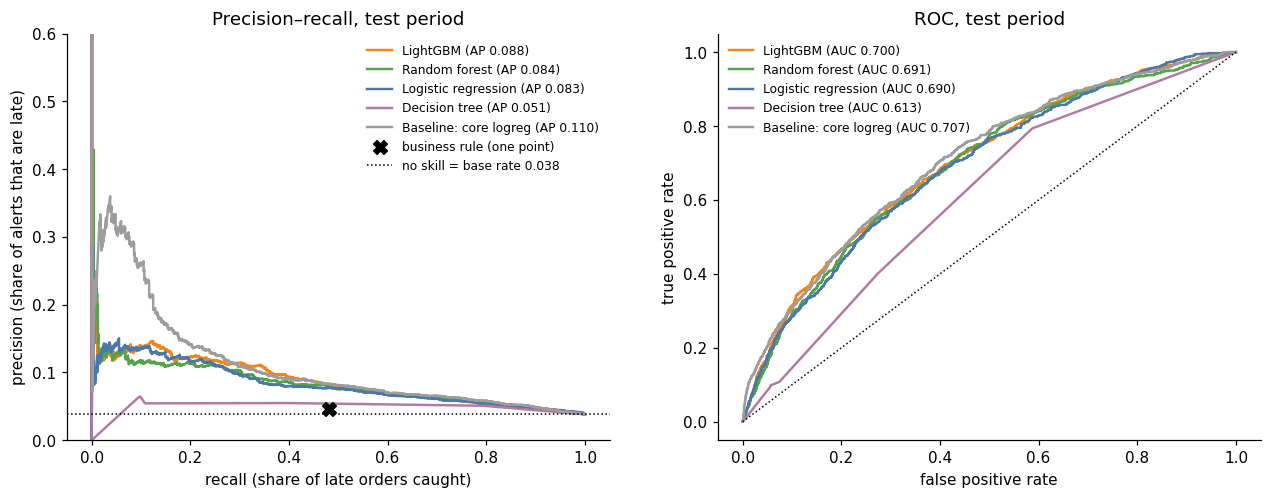

In [4]:
cols = {"lgbm": "#F58518", "forest": "#54A24B", "logreg": "#4C78A8", "tree": "#B279A2", "core_logreg": "#9D9D9D"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for k, c in cols.items():
    pr, rc, _ = precision_recall_curve(TEST.late_day, P[k]["test"])
    axes[0].plot(rc, pr, color=c, lw=1.6, label=f"{NAMES[k]} (AP {res.loc[NAMES[k], 'test_pr_auc']:.3f})")
    fpr, tpr, _ = roc_curve(TEST.late_day, P[k]["test"])
    axes[1].plot(fpr, tpr, color=c, lw=1.6, label=f"{NAMES[k]} (AUC {res.loc[NAMES[k], 'test_roc_auc']:.3f})")
rule = res.loc["Baseline: business rule"]
axes[0].scatter(rule.test_recall, rule.test_precision, marker="X", s=80, color="k", label="business rule (one point)", zorder=5)
axes[0].axhline(TEST.late_day.mean(), color="k", ls=":", lw=1, label=f"no skill = base rate {TEST.late_day.mean():.3f}")
axes[0].set_xlabel("recall (share of late orders caught)"); axes[0].set_ylabel("precision (share of alerts that are late)")
axes[0].set_ylim(0, 0.6); axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Precision–recall, test period")
axes[1].plot([0, 1], [0, 1], color="k", ls=":", lw=1); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].legend(frameon=False, fontsize=8); axes[1].set_title("ROC, test period")
save("pr_roc_curves"); plt.show()

## 3. Confusion matrices at the validation-chosen threshold

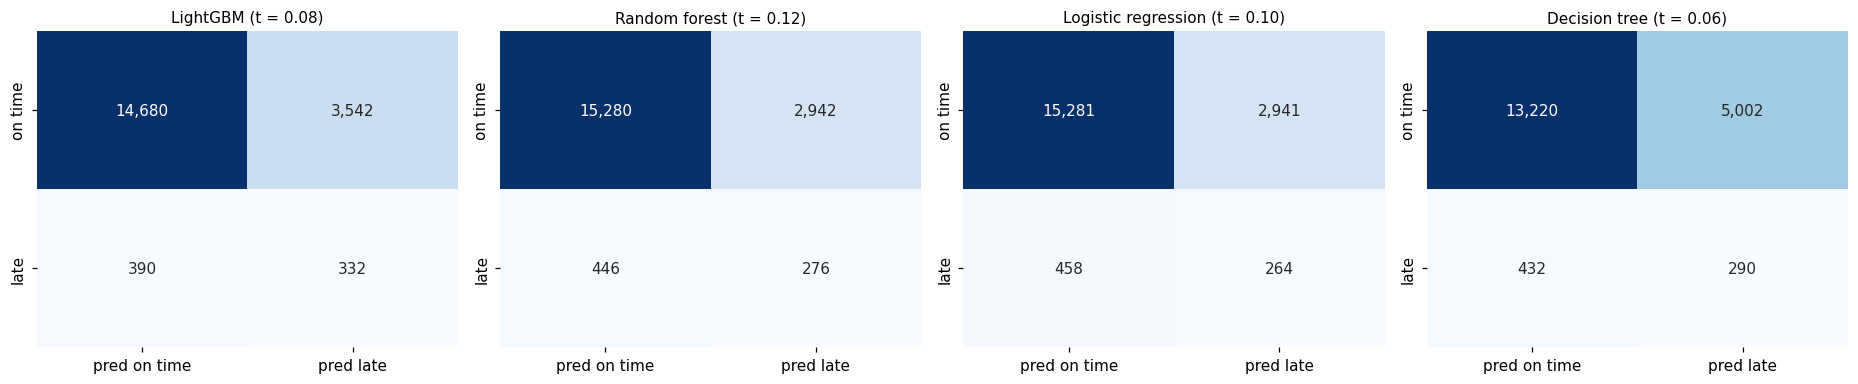

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, k in zip(axes, ["lgbm", "forest", "logreg", "tree"]):
    cm = confusion_matrix(TEST.late_day, P[k]["test"] >= THR[k])
    sns.heatmap(cm, annot=True, fmt=",", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["pred on time", "pred late"], yticklabels=["on time", "late"])
    ax.set_title(f"{NAMES[k]} (t = {THR[k]:.2f})", fontsize=10)
plt.tight_layout(); save("confusion_matrices"); plt.show()

## 4. Are the probabilities trustworthy? Calibration on test

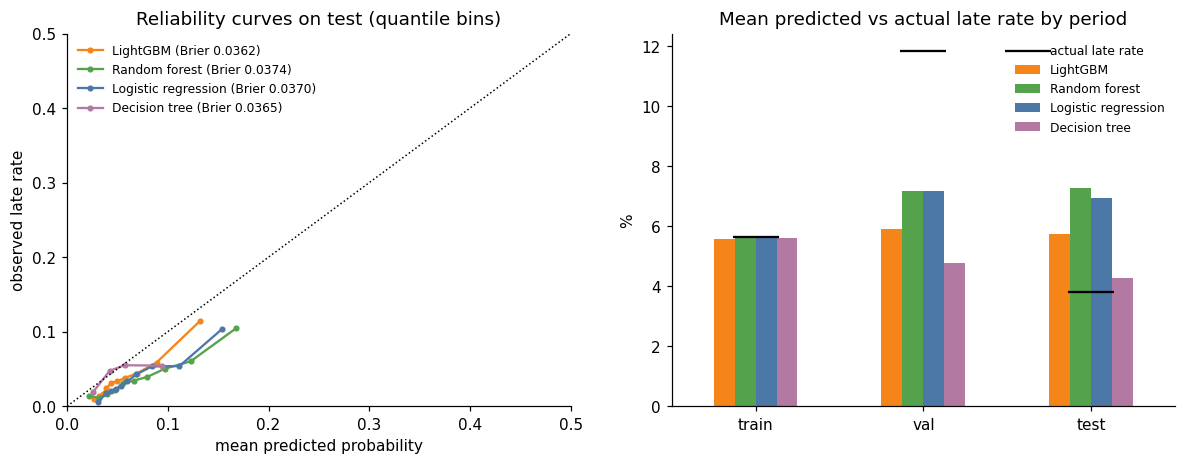

,LightGBM,Random forest,Logistic regression,Decision tree,actual
train,0.0557,0.0565,0.0564,0.0562,0.0564
val,0.0590,0.0719,0.0717,0.0478,0.1184
test,0.0574,0.0728,0.0694,0.0427,0.0381


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for k in ["lgbm", "forest", "logreg", "tree"]:
    fp, mp = calibration_curve(TEST.late_day, P[k]["test"], n_bins=10, strategy="quantile")
    axes[0].plot(mp, fp, marker="o", ms=3, color=cols[k], label=f"{NAMES[k]} (Brier {res.loc[NAMES[k], 'test_brier']:.4f})")
axes[0].plot([0, 0.5], [0, 0.5], color="k", ls=":", lw=1); axes[0].set_xlim(0, 0.5); axes[0].set_ylim(0, 0.5)
axes[0].set_xlabel("mean predicted probability"); axes[0].set_ylabel("observed late rate"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Reliability curves on test (quantile bins)")
mean_pred = pd.DataFrame({s: {NAMES[k]: P[k][s].mean() for k in ["lgbm", "forest", "logreg", "tree"]} for s in ["train", "val", "test"]})
actual = pd.Series({"train": TRAIN.late_day.mean(), "val": VAL.late_day.mean(), "test": TEST.late_day.mean()})
(mean_pred * 100).T.plot.bar(ax=axes[1], color=[cols[k] for k in ["lgbm", "forest", "logreg", "tree"]], rot=0)
axes[1].scatter(range(3), actual * 100, color="k", marker="_", s=900, zorder=5, label="actual late rate")
axes[1].set_ylabel("%"); axes[1].legend(frameon=False, fontsize=8); axes[1].set_title("Mean predicted vs actual late rate by period")
save("calibration"); plt.show()
mean_pred.T.assign(actual=actual).round(4)

**Finding.** Every model was trained in a world where 5.6% of orders are late, and it keeps predicting roughly that level whatever period it is applied to. On validation it predicts 4.8–7.2% against an actual 11.8%, so it under-predicts. On test it predicts 4.3–7.3% against an actual 3.8%, so it over-predicts (logistic regression 6.9%). The test Brier scores (0.036–0.037) are barely below the 0.0367 of a constant prediction at the test base rate. The models **rank** orders usefully, but their **probability level does not follow the drift**. Notebook 08 handles this with recalibration and retraining.

## 5. Performance month by month

In [7]:
best_val = res.loc[[NAMES[k] for k in ["lgbm", "forest", "logreg", "tree"]], "val_pr_auc"].idxmax()
BEST = {v: k for k, v in NAMES.items()}[best_val]
pm = pd.concat({NAMES[k]: per_period(TEST.late_day, P[k]["test"], TEST.purchase_ym)[["orders", "base_rate_%", "pr_auc", "lift"]]
                for k in ["lgbm", "logreg", "forest", "tree"]}, axis=1)
pm.to_csv(RESULTS / "07_per_month.csv")
print("best model on validation PR-AUC (chosen before looking at test):", best_val)
pm.round(3)

best model on validation PR-AUC (chosen before looking at test): Logistic regression


LightGBM                           Logistic regression                           Random forest                           Decision tree                          
          orders base_rate_% pr_auc   lift              orders base_rate_% pr_auc   lift        orders base_rate_% pr_auc   lift        orders base_rate_% pr_auc   lift
period                                                                                                                                                                  
2018-05     6749       6.564  0.128  1.950                6749       6.564  0.146  2.219          6749       6.564  0.109  1.657          6749       6.564  0.083  1.266
2018-06     6096       1.165  0.074  6.317                6096       1.165  0.042  3.574          6096       1.165  0.062  5.342          6096       1.165  0.025  2.145
2018-07     6099       3.410  0.070  2.058                6099       3.410  0.055  1.608          6099       3.410  0.078  2.288          6099       3.410  0.041  1.208

## 6. Is the best model really better? Paired bootstrap on test

The two models with the highest **validation** PR-AUC are compared on 1,000 bootstrap resamples of the test orders. Both models score the same resampled rows each time, so the comparison is paired.

In [8]:
top2 = res.loc[[NAMES[k] for k in ["lgbm", "forest", "logreg", "tree"]], "val_pr_auc"].sort_values(ascending=False).index[:2]
ka, kb = [{v: k for k, v in NAMES.items()}[n] for n in top2]
bd = bootstrap_diff(TEST.late_day, P[ka]["test"], P[kb]["test"], n=1000)
pairs = [(ka, kb)] + [(a, b) for a, b in [("lgbm", "logreg"), ("lgbm", "core_logreg"), ("logreg", "core_logreg")] if (a, b) != (ka, kb)]
boot = pd.DataFrame([{"A": NAMES[a], "B": NAMES[b], **bootstrap_diff(TEST.late_day, P[a]["test"], P[b]["test"], n=1000)} for a, b in pairs])
boot.to_csv(RESULTS / "07_bootstrap.csv", index=False)
boot.round(4)

,A,B,diff,ci_low,ci_high,share_a_better
0,Logistic regression,LightGBM,-0.0049,-0.0150,0.0042,0.137
1,LightGBM,Logistic regression,0.0049,-0.0042,0.0150,0.863
2,LightGBM,Baseline: core logreg,-0.0228,-0.0419,-0.0061,0.004
3,Logistic regression,Baseline: core logreg,-0.0277,-0.0468,-0.0113,0.000


**Finding.** The two models chosen on validation, logistic regression and LightGBM, are statistically indistinguishable on test. LightGBM minus logistic regression is +0.005 PR-AUC, 95% CI [−0.004, +0.015], with LightGBM ahead in 86% of resamples. The core baseline's lead is real, though: logistic regression is 0.028 worse (CI [−0.047, −0.011]) and LightGBM 0.023 worse (CI [−0.042, −0.006]); neither interval includes zero.

### Post-hoc diagnosis: why does the 5-feature baseline win on test?

This diagnosis comes after the test evaluation. It does not change any model; it only explains the result. The precision–recall curve shows the baseline's edge sits entirely in its top 5–10% of orders. Is that edge the `purchase_month` dummies, or simply the small feature set?

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
def small_lr(feats):
    pre = ColumnTransformer([("num", Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), feats)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000))]).fit(TRAIN[feats], TRAIN.late_day)
four = CORE_FEATURES[:-1]
m4 = small_lr(four)
diag = []
for name, p_val, p_test in [("core logreg, 5 features (with purchase_month)", P["core_logreg"]["val"], P["core_logreg"]["test"]),
                            ("core logreg, 4 features (no month)", m4.predict_proba(VAL[four])[:, 1], m4.predict_proba(TEST[four])[:, 1]),
                            ("tuned logistic regression, 42 features", P["logreg"]["val"], P["logreg"]["test"]),
                            ("tuned LightGBM, 42 features", P["lgbm"]["val"], P["lgbm"]["test"])]:
    top = np.argsort(-p_test)[: int(0.05 * len(p_test))]
    diag.append({"model": name, "val_pr_auc": scores(VAL.late_day, p_val)["pr_auc"], "test_pr_auc": scores(TEST.late_day, p_test)["pr_auc"],
                 "test_precision_top5%": TEST.late_day.iloc[top].mean()})
diag = pd.DataFrame(diag).set_index("model")
diag.to_csv(RESULTS / "07_posthoc_parsimony.csv")
diag.round(3)

,val_pr_auc,test_pr_auc,test_precision_top5%
model,,,
"core logreg, 5 features (with purchase_month)",0.138,0.110,0.146
"core logreg, 4 features (no month)",0.196,0.109,0.136
"tuned logistic regression, 42 features",0.221,0.083,0.118
"tuned LightGBM, 42 features",0.217,0.088,0.124


**Finding.** The month is not the explanation. Dropping `purchase_month` from the baseline leaves test PR-AUC unchanged (0.110 → 0.109), and validation actually *improves* (0.138 → 0.196). What wins on test is **the small feature set itself**: distance, promise length, seller as-of late rate and freight ratio. The 42-feature models win on validation (0.221 and 0.217 against 0.196) and lose on test (0.083 and 0.088 against 0.109), including in the top 5% of their rankings (precision 0.12 against 0.14).

The most plausible reading is a variance–robustness trade-off under regime change. The extra features, above all the 27 destination-state dummies and the regional late rates, encode *where* lateness was concentrated during the high-lateness months before validation. When the regime flipped to a 3.8%-late period, that geography stopped transferring. Distance, promise and seller reliability describe the physics of a delivery and stay stable. A single validation period that resembles the end of training cannot detect this.

**Lesson for the report:** choose models across several time periods, not one; and prefer compact models built on physical features when the environment is drifting.

## 7. Explainability

### 7.1 Global: what each model learned

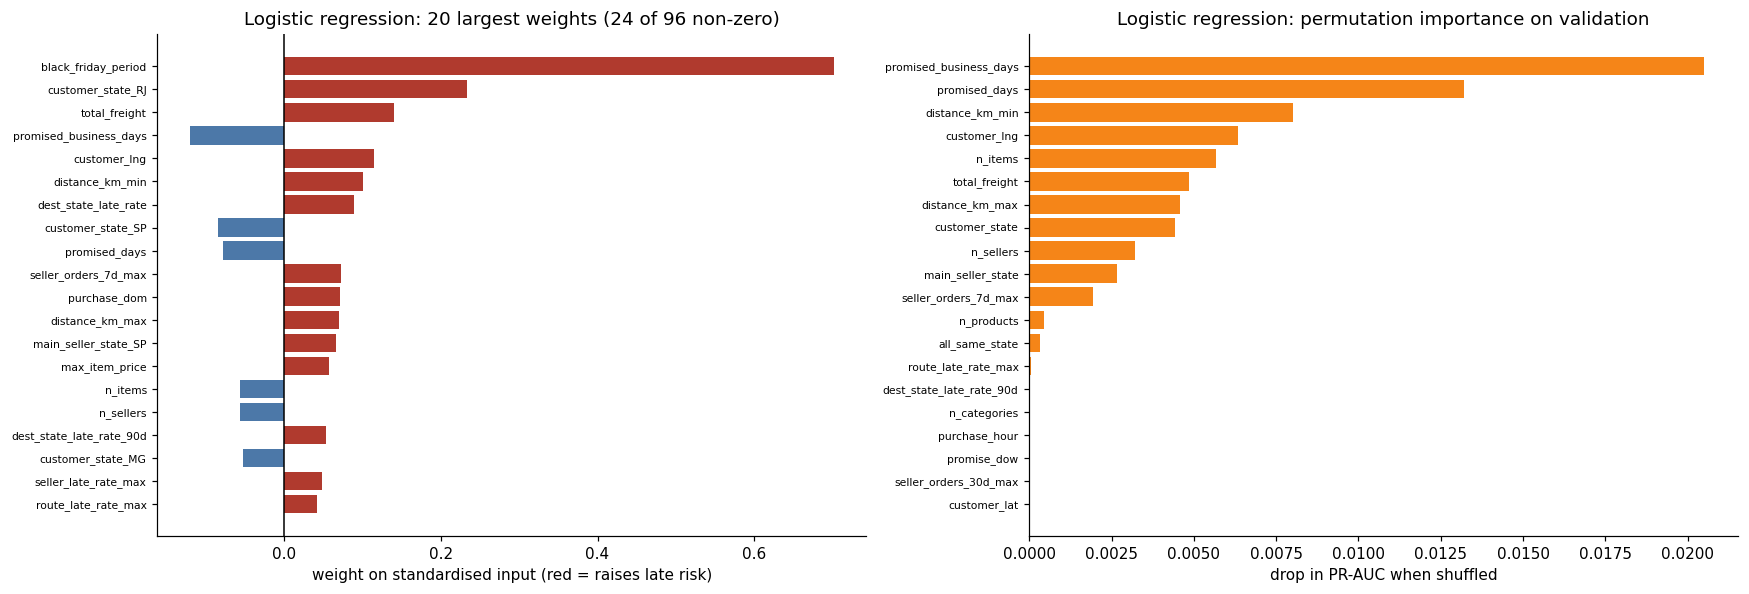

In [10]:
lr = models["logreg"]; w = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
w = w[w != 0]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top = w.reindex(w.abs().sort_values(ascending=False).index).head(20)[::-1]
axes[0].barh(top.index, top, color=np.where(top > 0, "#B03A2E", "#4C78A8")); axes[0].axvline(0, color="k", lw=1)
axes[0].tick_params(axis="y", labelsize=7); axes[0].set_title(f"Logistic regression: 20 largest weights ({len(w)} of {len(lr.named_steps['clf'].coef_[0])} non-zero)")
axes[0].set_xlabel("weight on standardised input (red = raises late risk)")
pi = permutation_importance(models[BEST], VAL[F], VAL.late_day.astype(int), scoring="average_precision", n_repeats=5,
                            random_state=C.SEED, n_jobs=5)
perm = pd.Series(pi.importances_mean, index=F).sort_values(ascending=False)
perm.to_csv(RESULTS / "07_permutation_importance_val.csv")
tp = perm.head(20)[::-1]
axes[1].barh(tp.index, tp, color="#F58518"); axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_title(f"{NAMES[BEST]}: permutation importance on validation"); axes[1].set_xlabel("drop in PR-AUC when shuffled")
plt.tight_layout(); save("global_importance"); plt.show()

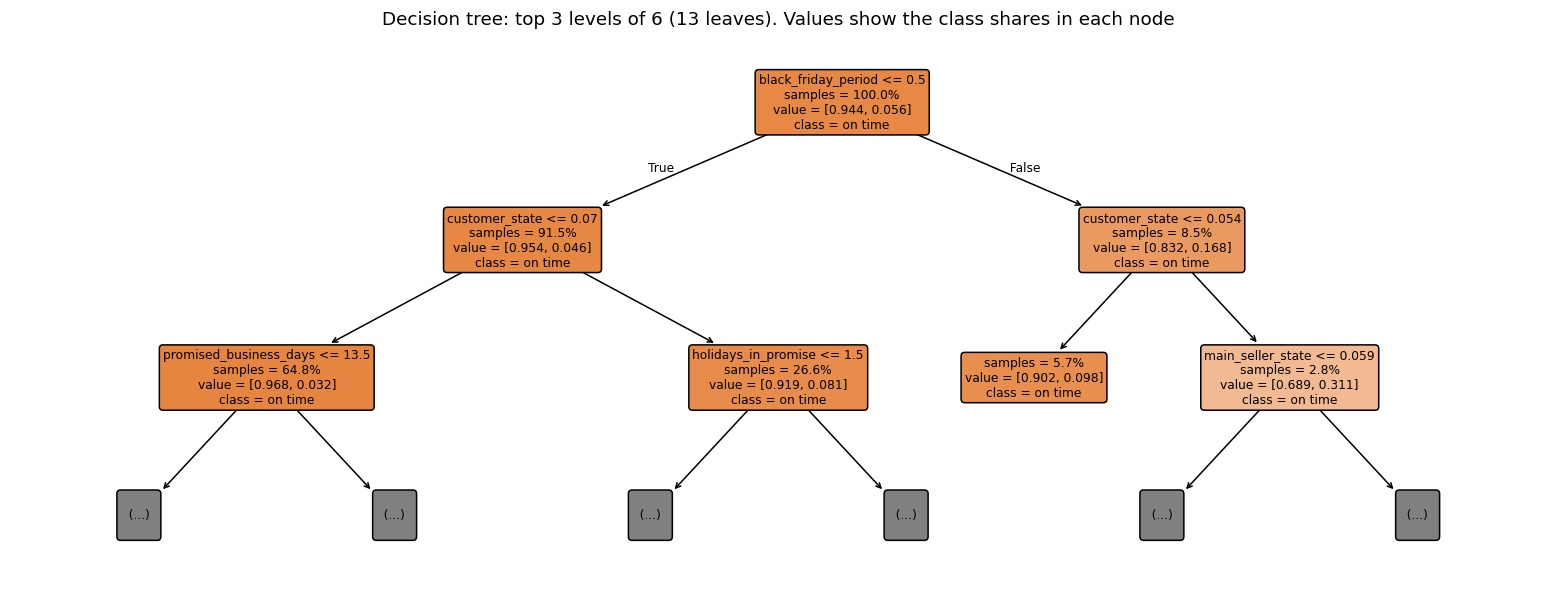

|--- black_friday_period <= 0.500
|   |--- customer_state <= 0.070
|   |   |--- promised_business_days <= 13.500
|   |   |   |--- class: 0.0
|   |   |--- promised_business_days >  13.500
|   |   |   |--- customer_lat <= -29.984
|   |   |   |   |--- class: 0.0
|   |   |   |--- customer_lat >  -29.984
|   |   |   |   |--- class: 0.0
|   |--- customer_state >  0.070
|   |   |--- holidays_in_promise <= 1.500
|   |   |   |--- customer_lng <= -38.729
|   |   |   |   |--- class: 0.0
|   |   |   |--- customer_lng >  -38.729
|   |   |   |   |--- class: 0.0
|   |   |--- holidays_in_promise >  1.500
|   |   |   |--- promised_days <= 32.500
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- promised_days >  32.500
|   |   |   |   |--- class: 0.0
|--- black_friday_period >  0.500
|   |--- customer_state <= 0.054
|   |   |--- class: 0.0
|   |--- customer_state >  0.054
|   |   |--- main_seller_state <= 0.059
|   |   |   |--- class: 0.0
|   |   |--- main_seller_state >  0.059
|   |   |

In [11]:
tree = models["tree"]
tn = tree.named_steps["pre"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(18, 6.5))
plot_tree(tree.named_steps["clf"], max_depth=2, feature_names=list(tn), class_names=["on time", "late"], filled=True,
          impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Decision tree: top 3 levels of {tree.named_steps['clf'].get_depth()} "
             f"({tree.named_steps['clf'].get_n_leaves()} leaves). Values show the class shares in each node")
save("tree_rules"); plt.show()
print(export_text(tree.named_steps["clf"], feature_names=list(tn), max_depth=3, decimals=3, show_weights=False)[:2500])

### 7.2 SHAP for LightGBM

SHAP splits each prediction into additive contributions, one per feature, in log-odds units. The beeswarm shows every test order as one dot per feature: its position is the contribution and its colour is the feature value (red = high).

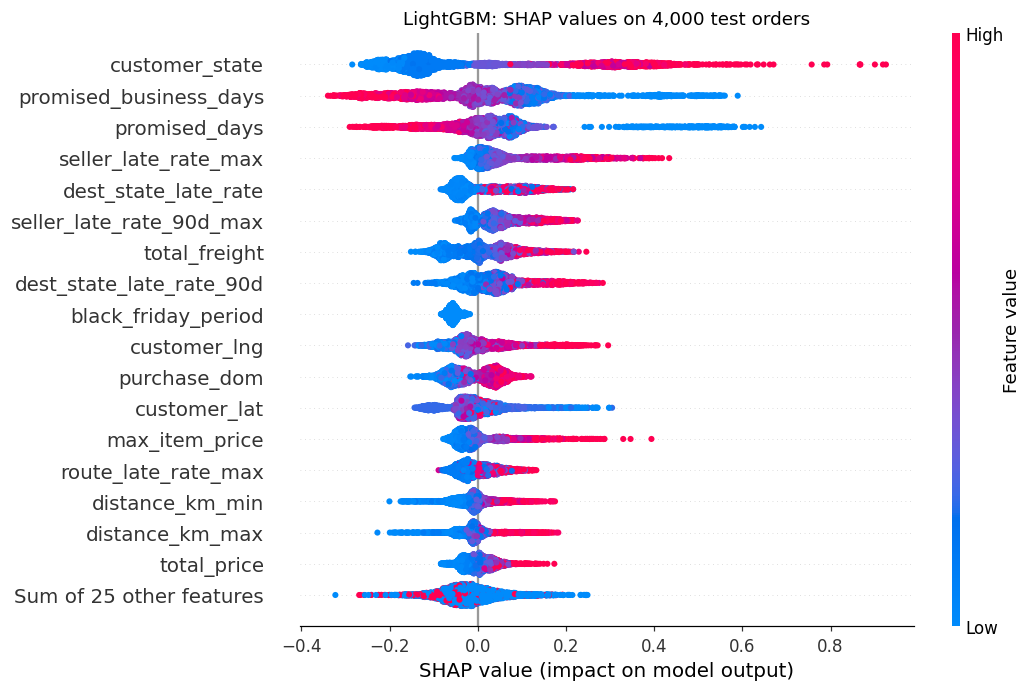

customer_state              0.1904
promised_business_days      0.1154
promised_days               0.0901
seller_late_rate_max        0.0713
dest_state_late_rate        0.0589
seller_late_rate_90d_max    0.0571
total_freight               0.0564
dest_state_late_rate_90d    0.0562
black_friday_period         0.0557
customer_lng                0.0508
purchase_dom                0.0457
customer_lat                0.0433
max_item_price              0.0408
route_late_rate_max         0.0324
distance_km_min             0.0310
dtype: float64

In [12]:
lgbm = models["lgbm"]
Xt_test = lgbm.named_steps["pre"].transform(TEST[F])
explainer = shap.TreeExplainer(lgbm.named_steps["clf"])
sample = Xt_test.sample(4000, random_state=C.SEED)
sv = explainer(sample)
plt.figure(); shap.plots.beeswarm(sv, max_display=18, show=False, plot_size=(9, 7))
plt.title("LightGBM: SHAP values on 4,000 test orders"); save("shap_beeswarm"); plt.show()
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=sample.columns).sort_values(ascending=False)
mean_abs.to_csv(RESULTS / "07_shap_mean_abs.csv")
mean_abs.head(15).round(4)

### 7.3 Local explanations: one correct alert, one missed late order, one false alarm

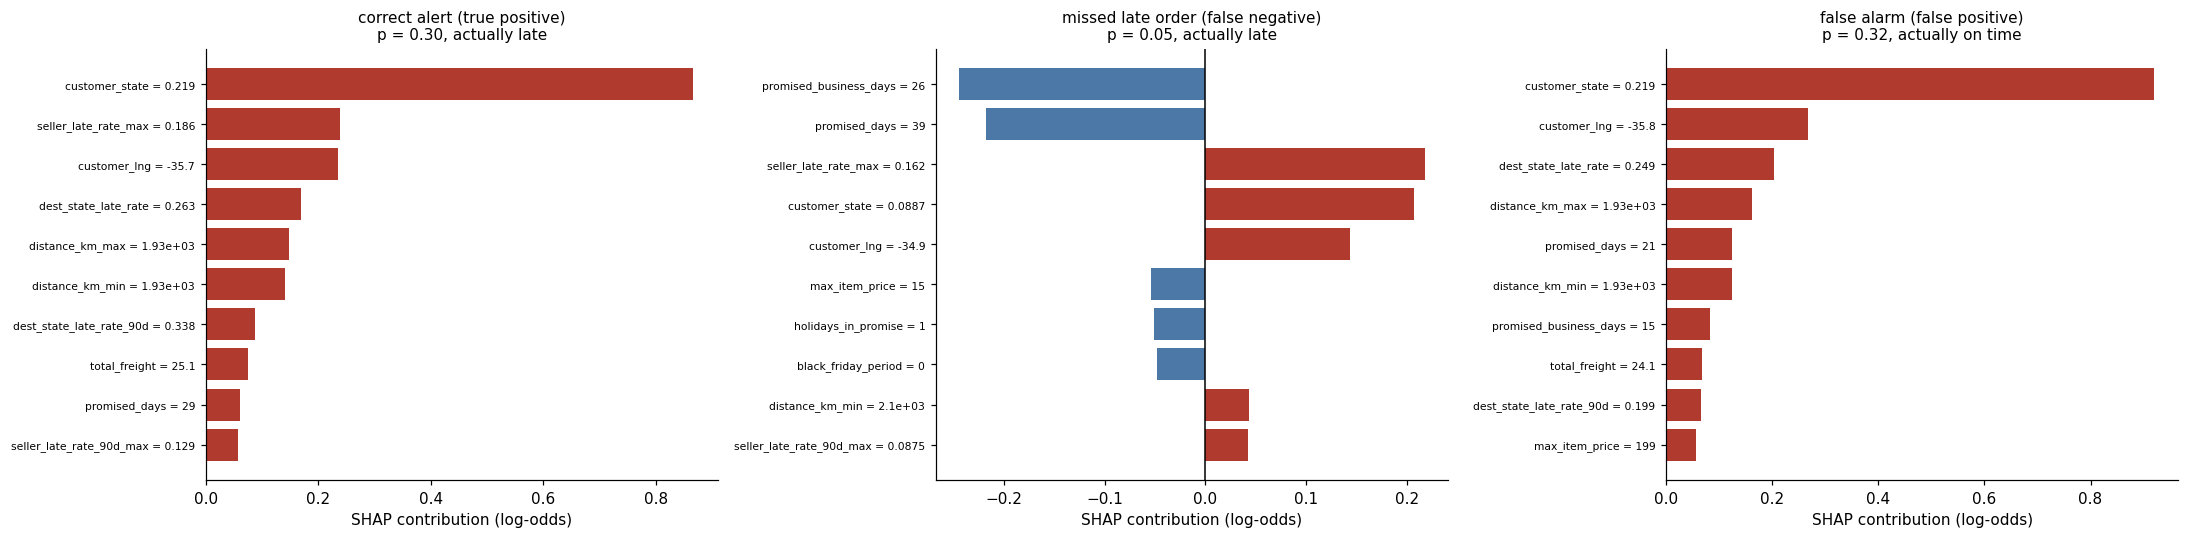

,order_id,p_late,actual,route,distance_km,promised_days,seller_late_rate,top_reasons
correct alert (true positive),f00c74caaa25430b1fa361c158e8996a,0.301,late,SP → AL,1934,29,0.186,"customer_state (+0.87), seller_late_rate_max (+0.24), cu..."
missed late order (false negative),3c0b55362db9e4d58bc57e08f27bc7f7,0.048,late,SP → PE,2102,39,0.162,"seller_late_rate_max (+0.22), customer_state (+0.21), cu..."
false alarm (false positive),b4454ac5d3550744c26cb851e267a889,0.318,on time,SP → AL,1929,21,0.072,"customer_state (+0.92), customer_lng (+0.27), dest_state..."


In [13]:
p_best, y_t, t_best = P["lgbm"]["test"], TEST.late_day.to_numpy(), THR["lgbm"]
cases = {
    "correct alert (true positive)": np.flatnonzero((y_t == 1) & (p_best >= t_best))[np.argmax(p_best[(y_t == 1) & (p_best >= t_best)])],
    "missed late order (false negative)": np.flatnonzero((y_t == 1) & (p_best < t_best))[np.argsort(p_best[(y_t == 1) & (p_best < t_best)])[len(p_best[(y_t == 1) & (p_best < t_best)]) // 2]],
    "false alarm (false positive)": np.flatnonzero((y_t == 0) & (p_best >= t_best))[np.argmax(p_best[(y_t == 0) & (p_best >= t_best)])],
}
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
reasons = {}
for ax, (title, i) in zip(axes, cases.items()):
    e = explainer(Xt_test.iloc[[i]])[0]
    contrib = pd.Series(e.values, index=Xt_test.columns)
    topc = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(10)[::-1]
    ax.barh([f"{c} = {Xt_test.iloc[i][c]:.3g}" for c in topc.index], topc, color=np.where(topc > 0, "#B03A2E", "#4C78A8"))
    ax.axvline(0, color="k", lw=1); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(f"{title}\np = {p_best[i]:.2f}, actually {'late' if y_t[i] else 'on time'}", fontsize=10)
    ax.set_xlabel("SHAP contribution (log-odds)")
    r = TEST.iloc[i]
    reasons[title] = {"order_id": r.order_id, "p_late": round(p_best[i], 3), "actual": "late" if y_t[i] else "on time",
                      "route": f"{r.main_seller_state} → {r.customer_state}", "distance_km": round(r.distance_km_max),
                      "promised_days": int(r.promised_days), "seller_late_rate": round(r.seller_late_rate_max, 3),
                      "top_reasons": ", ".join(f"{c} ({v:+.2f})" for c, v in contrib.sort_values(ascending=False).head(3).items())}
plt.tight_layout(); save("shap_local"); plt.show()
pd.DataFrame(reasons).T

**Reading the three cases** (LightGBM, threshold 0.076 chosen on validation):
* **Correct alert:** SP → AL, 1,934 km, 29-day promise, a seller with an 18.6% as-of late rate. Predicted 0.30. The destination state contributes most (+0.87 log-odds), followed by the seller's history (+0.24) and the distance.
* **Missed late order:** SP → PE, 2,102 km, but a **39-day promise** (26 business days). The long promise pulls the risk down (−0.25 and −0.22), outweighing the seller (+0.22) and the state (+0.21), so p = 0.05. The model trusts generous promises, and here the promise still broke.
* **False alarm:** SP → AL again (1,929 km, 21-day promise), p = 0.32, but delivered on time. Destination AL is a strong but **blunt** signal: the model knows AL is risky but cannot tell which AL orders will arrive safely.

## 8. Error slices: where does the model fail?

Recall and precision use the validation-chosen threshold; PR-AUC is threshold-free. Slices are defined only from checkout-time information.

In [14]:
REGION = {**{s: "North" for s in ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]},
          **{s: "Northeast" for s in ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]},
          **{s: "Center-West" for s in ["DF", "GO", "MT", "MS"]}, **{s: "Southeast" for s in ["ES", "MG", "RJ", "SP"]},
          **{s: "South" for s in ["PR", "RS", "SC"]}}
T = TEST.assign(p=p_best, flag=p_best >= t_best, region=TEST.customer_state.map(REGION))
heavy = TRAIN.total_weight_g.quantile(0.9)
slices = {
    **{f"region: {r}": T.region == r for r in ["Southeast", "South", "Center-West", "Northeast", "North"]},
    "new seller (cold start)": T.seller_cold_start == 1, "established seller": T.seller_cold_start == 0,
    "multi-seller order": T.n_sellers > 1, "single-seller order": T.n_sellers == 1,
    f"heavy parcel (> {heavy/1000:.1f} kg, train p90)": T.total_weight_g > heavy,
    "holiday within 7 days": T.holiday_within_7d == 1, "same state": T.all_same_state == 1, "cross state": T.all_same_state == 0,
    "short promise (≤ 15 days)": T.promised_days <= 15, "long promise (> 30 days)": T.promised_days > 30,
}
from sklearn.metrics import average_precision_score
sl = []
for name, m in slices.items():
    g = T[m]
    if g.late_day.sum() < 5:
        continue
    tp_ = (g.flag & (g.late_day == 1)).sum()
    sl.append({"slice": name, "orders": len(g), "late_%": g.late_day.mean() * 100, "pr_auc": average_precision_score(g.late_day, g.p),
               "lift": average_precision_score(g.late_day, g.p) / g.late_day.mean(),
               "recall": tp_ / g.late_day.sum(), "precision": tp_ / max(g.flag.sum(), 1)})
sl = pd.DataFrame(sl).set_index("slice")
sl.to_csv(RESULTS / "07_error_slices.csv")
sl.round(3)

,orders,late_%,pr_auc,lift,recall,precision
slice,,,,,,
region: Southeast,13266,3.400,0.092,2.695,0.388,0.079
region: South,2509,2.551,0.037,1.462,0.172,0.041
region: Center-West,1115,3.946,0.078,1.976,0.114,0.064
region: Northeast,1745,8.596,0.116,1.354,0.913,0.108
region: North,309,4.207,0.156,3.699,0.308,0.111
new seller (cold start),2450,3.510,0.084,2.398,0.547,0.082
established seller,16494,3.856,0.089,2.310,0.448,0.086
single-seller order,18633,3.869,0.088,2.274,0.459,0.086
"heavy parcel (> 6.7 kg, train p90)",1699,4.532,0.100,2.212,0.468,0.092


**Finding.** Ranking quality (lift = PR-AUC / base rate) holds up in most slices, at about 2.2–2.7×. Northeast orders are flagged almost wholesale (recall 0.91, precision 0.11), which is the "blunt state signal" from section 7.3. The **South is the weakest slice** (lift 1.5, recall 0.17): its late orders look like ordinary short trips. New sellers are handled as well as established ones (lift 2.4 against 2.3), so the smoothed as-of history copes with the cold start. Long promises (over 30 days) are rarely late (1.2%) and hard to rank. There were too few late multi-seller orders on test to score that slice.

## 9. The 20 most confident wrong predictions

In [15]:
T["error"] = np.where(T.late_day == 1, 1 - T.p, T.p)
wrong = T[(T.flag != (T.late_day == 1))].sort_values("error", ascending=False).head(20)
wrong_view = wrong[["order_id", "p", "late_day", "customer_state", "main_seller_state", "distance_km_max", "promised_days",
                    "seller_late_rate_max", "dest_state_late_rate", "n_items", "main_category"]].round(3)
wrong_view.to_csv(RESULTS / "07_confident_errors.csv", index=False)
print("false alarms among the 20:", int((wrong.late_day == 0).sum()), "| missed late orders:", int((wrong.late_day == 1).sum()))
wrong_view

false alarms among the 20: 0 | missed late orders: 20


,order_id,p,late_day,customer_state,main_seller_state,distance_km_max,promised_days,seller_late_rate_max,dest_state_late_rate,n_items,main_category
2579,646484e2931fb5d965e847f865fbc26a,0.025,1.0,PR,SP,336.725,22,0.068,0.057,1.0,livros_tecnicos
8298,b9174384bd0bd9634f2de4476da9d1e8,0.025,1.0,SP,PR,361.954,38,0.050,0.060,1.0,esporte_lazer
13203,6d05d2deb6a51438e65741cc19d715d8,0.025,1.0,PR,PR,353.001,30,0.079,0.056,1.0,cool_stuff
13746,885ae5d5896b9a5f3bd2a626876ace12,0.026,1.0,SP,SP,273.098,22,0.036,0.057,1.0,beleza_saude
14235,67a41e5f40c8ee15e8d00b64b363dfd0,0.026,1.0,SP,SP,417.774,21,0.032,0.056,1.0,beleza_saude
5021,b2059ed67ce144a36e2aa97d2c9e9ad2,0.027,1.0,SP,SP,30.018,25,0.096,0.058,1.0,moveis_escritorio
3490,c861c72a760c0b073de162e9e981509b,0.027,1.0,PR,SP,303.193,25,0.066,0.056,1.0,moveis_decoracao
3471,3090dd6007fdfb9b78972782cb7cfbd1,0.028,1.0,PR,SP,433.647,23,0.096,0.056,1.0,alimentos
3939,15b9bbc3bfc272e14a8da450ed7867c2,0.028,1.0,SP,PR,528.411,24,0.091,0.059,1.0,informatica_acessorios
4935,3abf6dc158567370b9270287cfcf25bd,0.028,1.0,SP,SP,587.819,19,0.062,0.058,1.0,livros_tecnicos


**Finding.** All 20 of the most confident mistakes are **missed late orders** with predicted risk of only 2.5–3%. They are short or medium trips inside the South and Southeast (SP, PR, MG), single items, ordinary promises, from sellers with low late rates. At checkout they look like the safest orders in the marketplace. Their lateness must come from events *after* checkout (carrier failures, stock problems, address issues) that no checkout-time feature can see. This is the irreducible part of Task A, and the reason precision stays modest.

In [16]:
json.dump({k: float(v) for k, v in THR.items()}, open(RESULTS / "07_thresholds_from_val.json", "w"), indent=2)
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 37.8s | final RSS 674 MB
